In [4]:
import pandas as pd

df = pd.read_csv("world_bank_dataset.csv")
print(df.shape)
print(df.columns.tolist())
df.head()

(200, 8)
['Country', 'Year', 'GDP (USD)', 'Population', 'Life Expectancy', 'Unemployment Rate (%)', 'CO2 Emissions (metric tons per capita)', 'Access to Electricity (%)']


,Country,Year,GDP (USD),Population,Life Expectancy,Unemployment Rate (%),CO2 Emissions (metric tons per capita),Access to Electricity (%)
0,Brazil,2010,1.493220e+12,829020000.0,66.7,3.81,10.79,76.76
1,Japan,2011,1.756270e+13,897010000.0,61.4,17.98,15.67,67.86
2,India,2012,1.642688e+13,669850000.0,69.1,16.02,2.08,81.08
3,Mexico,2013,1.189001e+13,113800000.0,80.1,6.26,19.13,53.46
4,India,2014,2.673020e+12,29710000.0,62.7,3.10,15.66,82.17


In [7]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv("world_bank_dataset.csv")
df.columns = ["Country","Year","GDP","Population","LifeExp","Unemployment","CO2","Electricity"]
df = df.dropna()

print(df.shape)
print(df["Country"].value_counts())
print(df.describe().round(2))

(200, 8)
Country
India             15
United Kingdom    13
Indonesia         13
Saudi Arabia      13
Italy             12
France            12
Argentina         12
United States     11
Mexico            10
Canada            10
Japan             10
Nigeria            9
Turkey             9
South Africa       8
Russia             8
China              8
Germany            7
Australia          7
Brazil             7
South Korea        6
Name: count, dtype: int64
          Year           GDP    Population  LifeExp  Unemployment     CO2  \
count   200.00  2.000000e+02  2.000000e+02   200.00        200.00  200.00   
mean   2014.50  1.056867e+13  7.387908e+08    66.32         13.27   10.06   
std       2.88  5.547703e+12  4.389956e+08     9.82          6.80    5.71   
min    2010.00  1.011720e+12  9.970000e+06    50.50          2.27    0.81   
25%    2012.00  5.774120e+12  3.533775e+08    57.78          6.81    4.88   
50%    2014.50  1.050615e+13  7.216700e+08    64.90         13.47    9.75  

In [8]:
corr = df.drop(columns=["Year"]).corr(numeric_only=True)
print(corr.round(2))

pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print(pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(5).round(3))

               GDP  Population  LifeExp  Unemployment   CO2  Electricity
GDP           1.00        0.04    -0.06         -0.01 -0.00        -0.15
Population    0.04        1.00    -0.10          0.03 -0.08         0.08
LifeExp      -0.06       -0.10     1.00         -0.09  0.02        -0.06
Unemployment -0.01        0.03    -0.09          1.00  0.04        -0.05
CO2          -0.00       -0.08     0.02          0.04  1.00        -0.03
Electricity  -0.15        0.08    -0.06         -0.05 -0.03         1.00
GDP         Electricity    -0.149
Population  LifeExp        -0.100
LifeExp     Unemployment   -0.089
Population  CO2            -0.081
            Electricity     0.075
dtype: float64


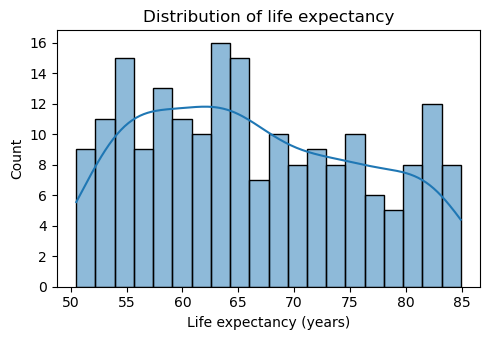

66.3245 64.9 9.818859391433596 0.246034689191006


In [10]:
# Plot 1 
col = "LifeExp"
plt.figure(figsize=(5,3.5))
sns.histplot(df[col], bins=20, kde=True)
plt.xlabel("Life expectancy (years)"); plt.ylabel("Count")
plt.title("Distribution of life expectancy")
plt.tight_layout()
plt.savefig("plot1.png", dpi=200)
plt.show()

print(df[col].mean(), df[col].median(), df[col].std(), df[col].skew())

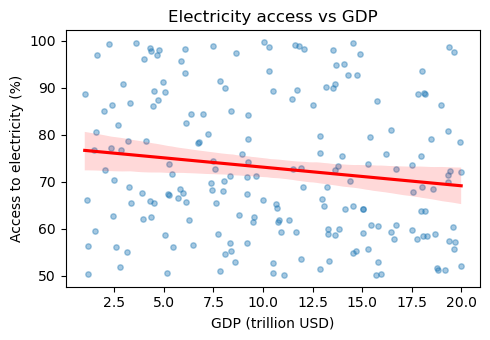

r = -0.149  p = 0.0353  R2 = 0.022
slope = -0.397  intercept = 77.07


In [12]:
# plot 2 
df["GDP_tn"] = df["GDP"] / 1e12      # GDP in trillions, easier to read

x, y = "GDP_tn", "Electricity"
plt.figure(figsize=(5,3.5))
sns.regplot(data=df, x=x, y=y, scatter_kws={"alpha":0.4,"s":15}, line_kws={"color":"red"})
plt.xlabel("GDP (trillion USD)"); plt.ylabel("Access to electricity (%)")
plt.title("Electricity access vs GDP")
plt.tight_layout()
plt.savefig("plot2.png", dpi=200)
plt.show()

r, p = stats.pearsonr(df[x], df[y])
res = stats.linregress(df[x], df[y])
print("r =", round(r,3), " p =", round(p,4), " R2 =", round(r**2,3))
print("slope =", round(res.slope,3), " intercept =", round(res.intercept,2))

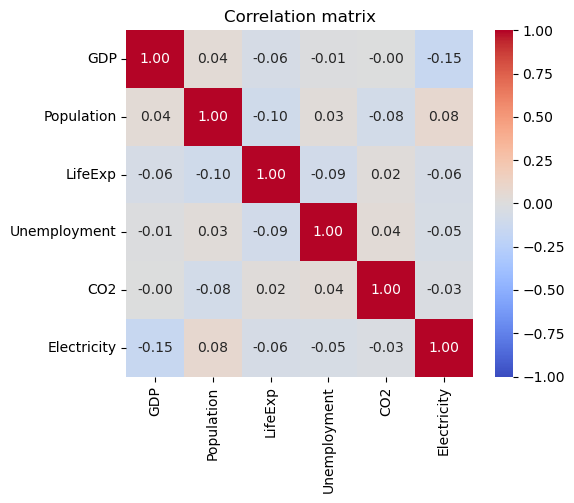

In [14]:
# plot 3 
corr = df.drop(columns=["Year","GDP_tn"]).corr(numeric_only=True)
plt.figure(figsize=(6,5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True)
plt.title("Correlation matrix")
plt.tight_layout()
plt.savefig("plot3.png", dpi=200)
plt.show()